LAB 3 - Ella Haynes

In [1]:
# import necessary packages
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import pandas as pd
import math

# this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (10, 10)

Problem 1

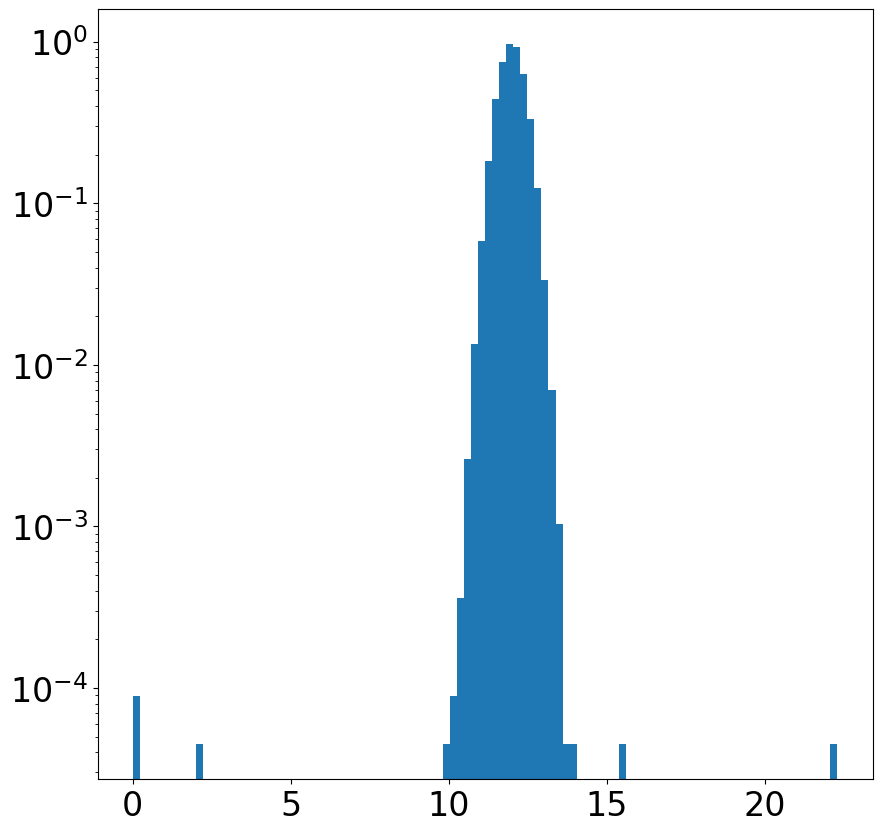

In [2]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d, 100, density = True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

Question A0 - Start by exploring the data you have created with appropriate plots.

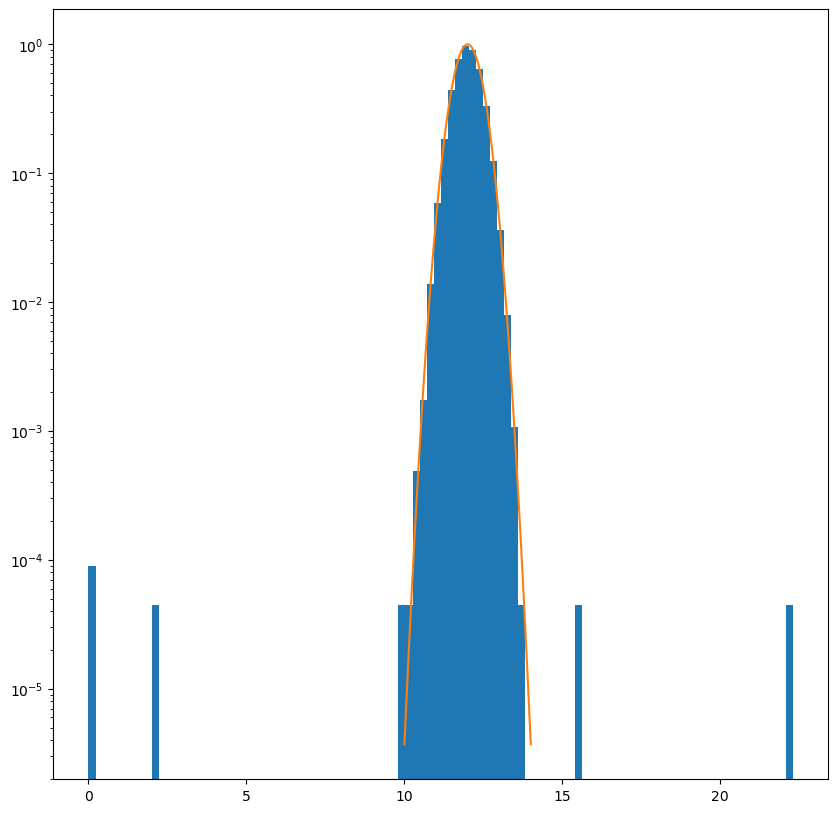

In [3]:
# generate data, including 'bad' data
d = np.append(stats.norm.rvs(loc = 12, scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])

# adding the gaussian fit line around the main peak
fig, ax = plt.subplots(1, 1)
ax.hist(d, 100, density = True)
plt.yscale('log')
x2 = np.linspace(10, 14, 1000)
ax.plot(x2, stats.norm.pdf(x2, loc = 12, scale = 0.4))

plt.show()

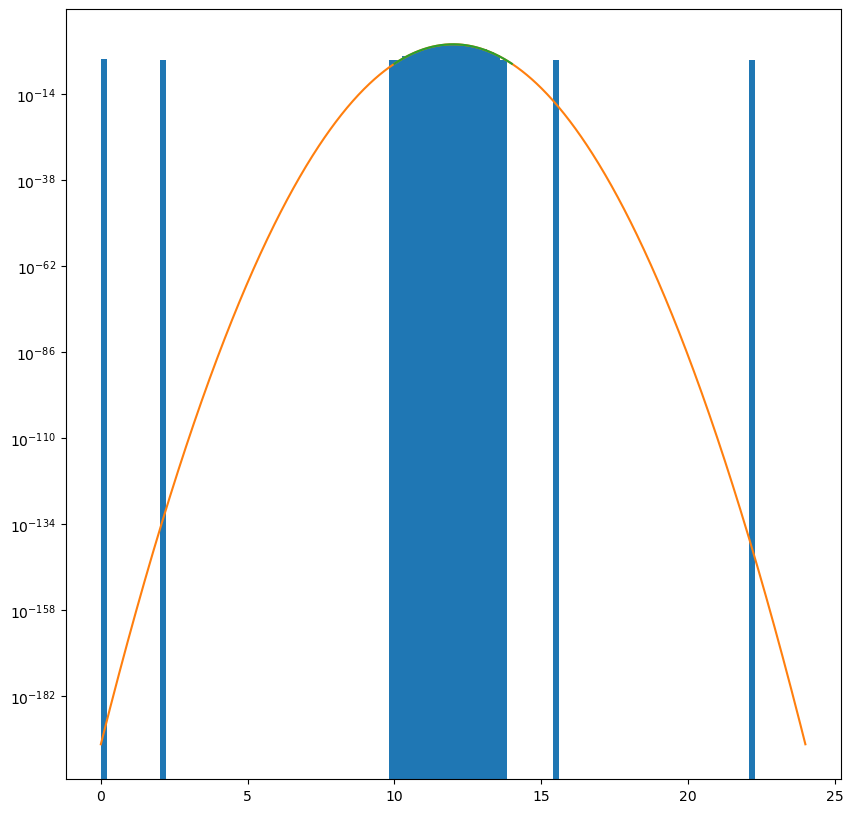

In [4]:
# adding the gaussian fit line around all data points
fig, ax = plt.subplots(1, 1)
ax.hist(d, 100, density = True)
plt.yscale('log')
x = np.linspace(0, 24, 1000)
ax.plot(x, stats.norm.pdf(x, loc = 12, scale = 0.4))
x2 = np.linspace(10, 14, 1000)
ax.plot(x2, stats.norm.pdf(x2, loc = 12, scale = 0.4))

plt.show()

Above, I added a normal fit line to help identify the shape of the distribution, and, as expected, it confirms the data is Gaussian. Some of the erroneous data points - from when the thermal control system misbehaved - can be identified because they are outside of this fit line around the main distribution. To demonstrate the error this causes, I added the fit line for a range which includes the bad data points, and, as shown above, the graph becomes distorted, and the fit, inaccurate.

Question A1 - State the statistical question in words. Be very clear, and describe why you have chosen this statistical question.

My Statistical Question: What data points are greater than 5 sigma away from the mean, indicating an error in the thermal control system at that time?

I have selected this statistical question because 5 sigma is the point at which a data point is considered a 'discovery' in astronomy, so to apply that logic to this problem, 5 sigma would identify the points at which it is likely the thermal control system behaved incorrectly.

Question A2 - Restate your question in math. Be very clear.

$\text{upper limit} = \mu + (\sigma \times 5)$

$\text{lower limit} = \mu - (\sigma \times 5)$

Question A3 - Apply your statistical test and construct a truth table.

In [5]:
# defining values
sigma = 5
mu = 12
scale = 0.4

# calculating upper and lower limits of 5 sigma
up_lim = mu + (scale * sigma)
low_lim = mu - (scale * sigma)

# constructing an array of bad data
bad_test = []
for num in d :
    if (num >= up_lim) or (num <= low_lim) :
        bad_test.append(num)

# printing
bad_test

[np.float64(10.0),
 np.float64(2.1),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(15.6),
 np.float64(22.3)]

In [6]:
# printing truth table as a pandas dataframe
truth_table = {
    ' ': ['Your Test True', 'Your Test Bad'],
    'True T': [f'99992', f'0'],
    'Bad T': [f'2', f'6']}

tt_df = pd.DataFrame(truth_table)
tt_df 

,,True T,Bad T
0,Your Test True,99992,2
1,Your Test Bad,0,6


Question B - How does the number of omissions, where you threw out good data, depend on the statistical threshold you chose and is it a predictable quantity?

If you select too low of a statistical threshold, your method would incorrectly identify good data as bad within the main portion of the distribution, and good data which have unexpectedly low or high values. It is not a very predictable quantity because randomly generated data may produce true data at unusally high or low values, which end up ommitted because they are unusual. My method did not throw out any good data, as observable in the truth table above (where 'True T' and 'Your Test Bad' equals 0). 

Question C - Are there mistakes of commission (bad data getting in)? If yes, are they avoidable and how do they depend on your statistical threshold?

Yes, my data incorrectly classifies 2 data points as good, when they are in fact bad (under 'Bad T' and 'Your Test True'). My statistical threshold was for the data to be 5 sigma away from the mean, and upon reviewing the results, the threshold may need to be slightly lowered, however, if done, good data risks getting thrown out. This is not the most avoidable issue as bad data may fall within expected ranges, and thus get counted, however, carefully selecting a higher statistical threshold can make your method more accurate and prevent bad data from getting in as much as possible.

Problem 2

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_736/3361331956.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel('$\Delta$y arcseconds')
/tmp/ipykernel_736/3361331956.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel('$\Delta$x arcseconds')


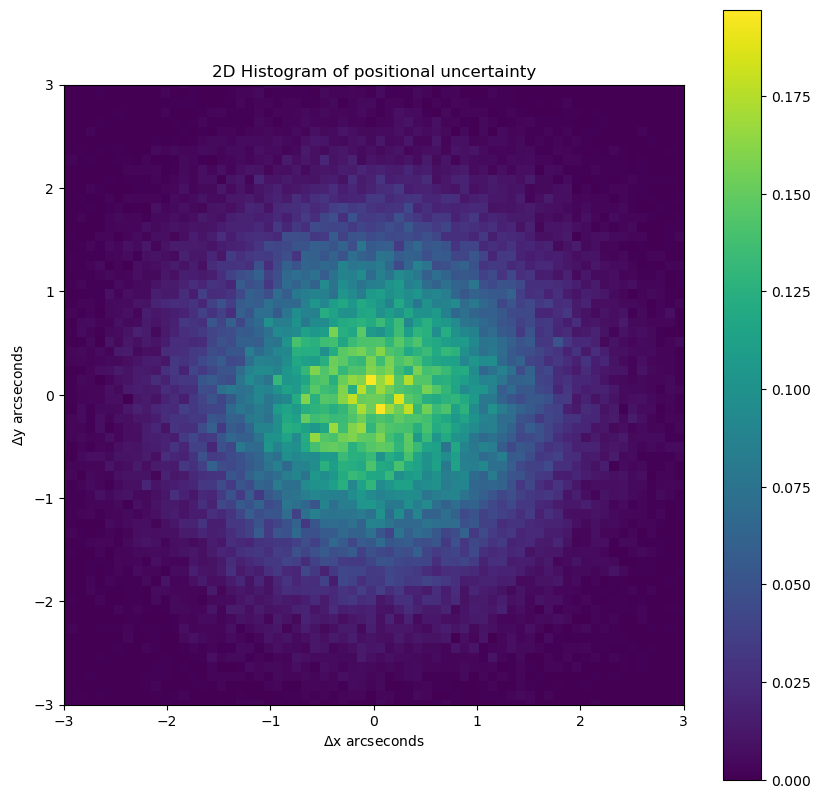

In [7]:
a = np.vstack((stats.norm.rvs(scale = 1, size = 100000), stats.norm.rvs(scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0, :], a[1, :], bins = 100, density = True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title('2D Histogram of positional uncertainty')
plt.ylabel('$\Delta$y arcseconds')
plt.xlabel('$\Delta$x arcseconds')
plt.colorbar(h[3], ax = ax)

Question 1 - If I have a potential asteroid, it will have some true movement between the images. We would like a '5 sigma' detection of movement. What is that distance in arcseconds? What is the question in words?

My Statistical Question: What is the distance (in arcseconds) of five sigma away from the mean on the 2D Gaussian plot - the point at which an asteroid can be classified as such?

Question 2 - What is the question in math?

$(1-\int_{0}^{5\sigma}e^{\frac{-x^{2}}{2\sigma^{2}}}dx)^{-1}$

This combination of the inverse survival function and the Rayleigh PDF formula returns the probability of the event occuring. This can then been converted into distance corresponding to a given sigma.

Question 3 - What distance in arcseconds represents a 5 sigma detection of motion?

In [8]:
# sqrt(x^2 + y^2) = the Rayleigh distribution if x and y are standard normal distributions
# the five sigma probability of the standard Rayleigh distribution:
prob = 2.87e-7
distance = stats.rayleigh.isf(prob, loc = 0, scale = 1)

print(f'The distance of 5 sigma is {distance:.2f}.')

The distance of 5 sigma is 5.49.


Problem 3

Question 1 - What is the question in words?

My Statistical Question: Is an observation of 6800 cosmic rays significant (at least 5 sigma from the mean) in an observation window of 15 days and 8 hours per night, and a observation space of the moon in the sky?

Question 2 - Translate the question to math, describing both the expected background pdf() and the integral you need to do.

The PDF must not be negative and must be discrete -> Poisson Distribution. The representative integral is as follows:

$(1-\int_{0}^{6800} \frac{\lambda^{k}e^{-\lambda}}{k!}d\lambda)^{-1}$

Question 3 - Convert to sigma.

In [9]:
# defining the values, per the problem
k = 6800
mu = 8 * 60 * 15

# calculating probability
prob = stats.poisson.cdf(k = k, mu = mu, loc = 0)

# calculating sigma of the probability
sigma = stats.norm.isf(prob, loc = 0, scale = 1)

# printing
print(f'This observation is not quite - but is on the cusp of being - significant at {sigma:.2f} sigma.')

This observation is not quite - but is on the cusp of being - significant at 4.75 sigma.
